In [ ]:
import numpy as np 
import matplotlib.pyplot as plt 
import pandas as pd


random_state = 272
np.random.seed(random_state)

In [45]:
df = pd.read_csv('./USA_housing_toy.csv')
df.head()

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price,Address
0,79545.45857,5.682861,7.009188,4.09,23086.80050,1.059034e+06,"208 Michael Ferry Apt. 674\nLaurabury, NE 3701..."
1,79248.64245,6.002900,6.730821,3.09,40173.07217,1.505891e+06,"188 Johnson Views Suite 079\nLake Kathleen, CA..."
2,61287.06718,5.865890,8.512727,5.13,36882.15940,1.058988e+06,"9127 Elizabeth Stravenue\nDanieltown, WI 06482..."
3,63345.24005,7.188236,5.586729,3.26,34310.24283,1.260617e+06,USS Barnett\nFPO AP 44820
4,59982.19723,5.040555,7.839388,4.23,26354.10947,6.309435e+05,USNS Raymond\nFPO AE 09386


In [46]:
df.isnull().sum()

Avg. Area Income                0
Avg. Area House Age             0
Avg. Area Number of Rooms       0
Avg. Area Number of Bedrooms    0
Area Population                 0
Price                           0
Address                         0
dtype: int64

In [47]:
df.describe()

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price
count,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2.500000e+03
mean,68593.117818,5.980941,7.005079,3.989816,36032.881352,1.233117e+06
std,10696.969146,1.007664,1.002411,1.241848,9803.908974,3.547254e+05
min,17796.631190,2.644304,3.236194,2.000000,172.610686,3.114052e+04
25%,61461.357480,5.328918,6.311252,3.150000,29381.948903,9.937032e+05
50%,68709.189825,5.981525,7.024682,4.050000,36073.859200,1.235056e+06
75%,75868.888025,6.680616,7.687694,4.500000,42683.564510,1.467923e+06
max,107701.748400,8.991399,10.759588,6.500000,69592.040240,2.469066e+06


In [48]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 7 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Avg. Area Income              2500 non-null   float64
 1   Avg. Area House Age           2500 non-null   float64
 2   Avg. Area Number of Rooms     2500 non-null   float64
 3   Avg. Area Number of Bedrooms  2500 non-null   float64
 4   Area Population               2500 non-null   float64
 5   Price                         2500 non-null   float64
 6   Address                       2500 non-null   str    
dtypes: float64(6), str(1)
memory usage: 136.8 KB


In [49]:
X = df[['Avg. Area Income','Avg. Area House Age','Avg. Area Number of Rooms','Avg. Area Number of Bedrooms','Area Population']]
X

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population
0,79545.45857,5.682861,7.009188,4.09,23086.80050
1,79248.64245,6.002900,6.730821,3.09,40173.07217
2,61287.06718,5.865890,8.512727,5.13,36882.15940
3,63345.24005,7.188236,5.586729,3.26,34310.24283
4,59982.19723,5.040555,7.839388,4.23,26354.10947
...,...,...,...,...,...
2495,70213.64600,5.913557,5.829801,3.26,34386.42978
2496,48640.10361,3.664294,8.609398,4.07,33381.23866
2497,64534.46591,3.883364,7.382973,4.22,52933.67258
2498,58337.23049,5.233592,5.683635,2.18,38235.03310


In [50]:
y = df['Price']
y

0       1.059034e+06
1       1.505891e+06
2       1.058988e+06
3       1.260617e+06
4       6.309435e+05
            ...     
2495    1.064570e+06
2496    6.072494e+05
2497    1.202228e+06
2498    8.168135e+05
2499    1.598159e+06
Name: Price, Length: 2500, dtype: float64

In [51]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.4, random_state=random_state)

In [52]:
from sklearn.preprocessing import StandardScaler
scalar = StandardScaler()
X_train = scalar.fit_transform(X_train)
X_test = scalar.transform(X_test)


In [53]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](5,)","[241166.44,162093.21,119105.49, -382.81,148911.55]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,1.231e+06
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,5
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(5)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](5,)","[46.86,39.29,38.69,38.11,28.48]"


In [54]:
print(f"Intercept: {model.intercept_}")


Intercept: 1231034.947415187


In [55]:
coeff_df = pd.DataFrame(model.coef_,X.columns,columns=['Coefficient'])
coeff_df

,Coefficient
Avg. Area Income,241166.438469
Avg. Area House Age,162093.210742
Avg. Area Number of Rooms,119105.490597
Avg. Area Number of Bedrooms,-382.808082
Area Population,148911.546167


In [ ]:
print("Interpreting the co-efficients")
for index,row in coeff_df.iterrows():
    feature = index
    coefficient = row['Coefficient']

    change_type = 'increase' if coefficient >= 0 else 'negative'
    formatted_coefficient = f'${abs(coefficient):,.2f}'
    print(f"- Holding all other features fixed, a 1 unit increase in {feature} is associated with an {change_type} of {formatted_coefficient}.")


Interpreting the co-efficients
- Holding all other features fixed, a 1 unit increase in Avg. Area Income is associated with an increase of $148,911.55.
- Holding all other features fixed, a 1 unit increase in Avg. Area House Age is associated with an increase of $148,911.55.
- Holding all other features fixed, a 1 unit increase in Avg. Area Number of Rooms is associated with an increase of $148,911.55.
- Holding all other features fixed, a 1 unit increase in Avg. Area Number of Bedrooms is associated with an negative of $148,911.55.
- Holding all other features fixed, a 1 unit increase in Area Population is associated with an increase of $148,911.55.


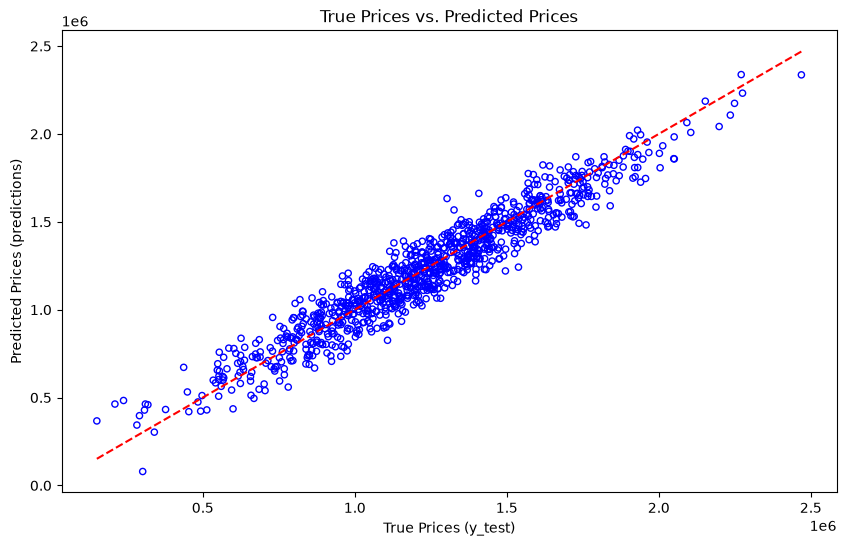

In [64]:
predictions = model.predict(X_test)
plt.figure(figsize=(10,6))
plt.scatter(y_test, predictions,s=20,facecolors='none',edgecolors='blue')
plt.xlabel("True Prices (y_test)")
plt.ylabel("Predicted Prices (predictions)")
plt.title("True Prices vs. Predicted Prices")
plt.plot([y_test.min(),y_test.max()],[y_test.min(),y_test.max()],'r--',label='Zero Error line')

In [ ]:
from sklearn import metrics

print(f"MAE:{metrics.mean_absolute_error(y_test,predictions)}")
print(f"MSE:{metrics.mean_squared_error(y_test,predictions)}")
print(f"RMSE:{np.sqrt(metrics.mean_squared_error(y_test,predictions))}")
print(f"R2 Score:{metrics.r2_score(y_test,predictions)}")

MAE:81428.75254620622
MSE:10159472913.275927
RMSE:100794.21071309566
R2 Score:0.9166061358275313


: 